In [29]:
import pandas as pd
import streamlit as st
import matplotlib.pyplot as plt
import numpy as np
from fuzzywuzzy import process
import groq
import os
os.system("pip install groq")
import groq
from PIL import Image
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity
import seaborn as sns
%matplotlib inline

In [30]:
fut_base = pd.read_csv('Futbase.csv')

C:\Users\josen\AppData\Local\Temp\ipykernel_16064\3018508110.py:1: DtypeWarning: Columns (39) have mixed types. Specify dtype option on import or set low_memory=False.
  fut_base = pd.read_csv('Futbase.csv')


In [31]:
fut_base.head()

,player_id,player_url,fifa_version,fifa_update,fifa_update_date,short_name,long_name,player_positions,overall,potential,...,cdm,rdm,rwb,lb,lcb,cb,rcb,rb,gk,player_face_url
0,252371,/player/252371/jude-bellingham/260004/,26,4,2025-09-19,J. Bellingham,Jude Victor William Bellingham,"CAM, CM",90,94,...,85+3,85+3,83+3,82+3,81+3,81+3,81+3,82+3,18+3,https://cdn.sofifa.net/players/252/371/26_120.png
1,239053,/player/239053/federico-valverde/260004/,26,4,2025-09-19,F. Valverde,Federico Santiago Valverde Dipetta,"CM, CDM, RB",89,90,...,87+3,87+3,86+3,86+3,83+3,83+3,83+3,86+3,18+3,https://cdn.sofifa.net/players/239/053/26_120.png
2,212622,/player/212622/joshua-kimmich/260004/,26,4,2025-09-19,J. Kimmich,Joshua Walter Kimmich,"CDM, RB, CM",89,89,...,87+2,87+2,86+3,85+3,82+3,82+3,82+3,85+3,21+3,https://cdn.sofifa.net/players/212/622/26_120.png
3,235212,/player/235212/achraf-hakimi/260004/,26,4,2025-09-19,A. Hakimi,Achraf Hakimi Mouhأشرف حكيمي,"RB, RM",89,90,...,83+3,83+3,86+3,86+3,81+3,81+3,81+3,86+3,17+3,https://cdn.sofifa.net/players/235/212/26_120.png
4,224232,/player/224232/nicolo-barella/260004/,26,4,2025-09-19,N. Barella,Nicolò Barella,CM,87,87,...,85+2,85+2,84+3,83+3,80+3,80+3,80+3,83+3,19+3,https://cdn.sofifa.net/players/224/232/26_120.png


In [32]:
OUTPUT_COLUMNS = ['player_id', 'short_name', 'long_name', 'age', 'nationality_name', 'club_name', 'player_positions',
                  'overall', 'potential', 'height_cm', 'weight_kg', 'pace', 'movement_acceleration', 
                  'movement_sprint_speed', 'movement_agility', 'movement_balance', 'power_strength', 
                  'power_stamina', 'power_jumping', 'attacking_finishing', 'attacking_short_passing', 
                  'skill_ball_control', 'skill_dribbling', 'skill_curve', 'attacking_crossing', 
                  'power_long_shots', 'passing', 'shooting', 'dribbling', 'mentality_vision', 
                  'mentality_composure', 'mentality_positioning', 'mentality_aggression', 
                  'mentality_interceptions', 'work_rate', 'international_reputation', 
                  'defending_marking_awareness', 'defending_standing_tackle', 'defending_sliding_tackle',
                  'goalkeeping_diving', 'goalkeeping_handling', 'goalkeeping_kicking', 
                  'goalkeeping_positioning', 'goalkeeping_reflexes', 'value_eur', 'wage_eur', 
                  'release_clause_eur', 'club_contract_valid_until_year']

fut_base = fut_base[OUTPUT_COLUMNS]

In [33]:
age_counts = fut_base['age'].value_counts().sort_index()
print("Distribution of players by age:")
print(age_counts)

print("\nYoungest players:")
print(f"Minimum age: {fut_base['age'].min()}")
print(fut_base[fut_base['age'] == fut_base['age'].min()][['short_name', 'age', 'club_name']].head())

Distribution of players by age:
age
16      34
17     284
18     649
19    1032
20    1357
21    1387
22    1427
23    1324
24    1389
25    1435
26    1182
27    1139
28    1092
29    1060
30     789
31     710
32     610
33     492
34     353
35     272
36     156
37     100
38      65
39      30
40      17
41       9
42       5
43       3
44       3
Name: count, dtype: int64

Youngest players:
Minimum age: 16
       short_name  age       club_name
6665   R. Ngumoha   16       Liverpool
7517      L. Page   16  Leicester City
10187   N. De Cat   16  RSC Anderlecht
11147    J. Evans   16  Leicester City
11534  A. Ledesma   16    Club Olimpia


In [34]:
fut_base.head()

,player_id,short_name,long_name,age,nationality_name,club_name,player_positions,overall,potential,height_cm,...,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,value_eur,wage_eur,release_clause_eur,club_contract_valid_until_year
0,252371,J. Bellingham,Jude Victor William Bellingham,22,England,Real Madrid,"CAM, CM",90,94,186,...,77,14,11,10,5,8,174500000,320000,370800000.0,2029.0
1,239053,F. Valverde,Federico Santiago Valverde Dipetta,26,Uruguay,Real Madrid,"CM, CDM, RB",89,90,182,...,86,6,10,6,15,8,120500000,340000,256100000.0,2029.0
2,212622,J. Kimmich,Joshua Walter Kimmich,30,Germany,FC Bayern München,"CDM, RB, CM",89,89,177,...,85,8,15,7,15,15,86000000,140000,141900000.0,2029.0
3,235212,A. Hakimi,Achraf Hakimi Mouhأشرف حكيمي,26,Morocco,Paris Saint-Germain,"RB, RM",89,90,181,...,79,10,8,14,6,8,111000000,170000,213700000.0,2029.0
4,224232,N. Barella,Nicolò Barella,28,Italy,Inter,CM,87,87,175,...,80,11,5,13,14,11,79500000,69000,131199999.0,2029.0


Total number of players aged 16-20: 18405

Top young players (sorted by overall rating):


,short_name,age,overall,potential,club_name
0,J. Bellingham,22,90,94,Real Madrid
1,F. Valverde,26,89,90,Real Madrid
2,J. Kimmich,30,89,89,FC Bayern München
3,A. Hakimi,26,89,90,Paris Saint-Germain
4,N. Barella,28,87,87,Inter
5,H. Çalhanoğlu,31,86,86,Inter
6,F. Dimarco,27,85,85,Inter
7,A. Mac Allister,26,87,88,Liverpool
8,Rodri,29,90,90,Manchester City
9,A. Griezmann,34,85,85,Atlético Madrid


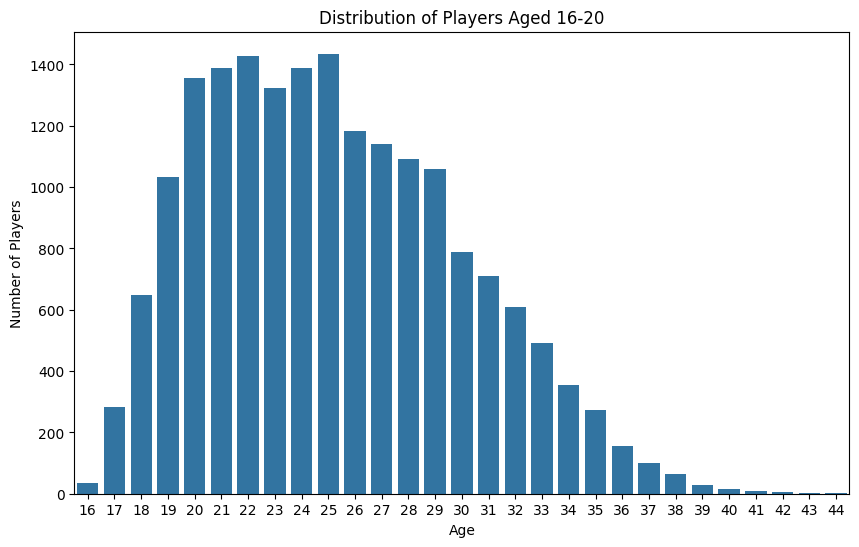

In [35]:
fut_base[(fut_base['age'] >= 16) & (fut_base['age'] <= 20)]
print(f"Total number of players aged 16-20: {len(fut_base)}")

# Display the young players sorted by overall rating
fut_base.sort_values(by='overall', ascending=False)
print("\nTop young players (sorted by overall rating):")
display(fut_base[['short_name', 'age', 'overall', 'potential', 'club_name']].head(10))

# Create a bar plot showing the distribution of young players by age
plt.figure(figsize=(10, 6))
age_distribution = fut_base['age'].value_counts().sort_index()
sns.barplot(x=age_distribution.index, y=age_distribution.values)
plt.title('Distribution of Players Aged 16-20')
plt.xlabel('Age')
plt.ylabel('Number of Players')
plt.show()

In [ ]:
# Filtrar el dataset para quedarse solo con jugadores de 16 a 21 años (incluidos)
fut_base = fut_base[(fut_base['age'] >= 16) & (fut_base['age'] <= 21)].reset_index(drop=True)

# Mostrar resumen rápido
print(f"Nº jugadores (16-21): {len(fut_base)}")
print("Distribución por edad:")
print(fut_base['age'].value_counts().sort_index())

Nº jugadores (16-21): 4743
Distribución por edad:
age
16      34
17     284
18     649
19    1032
20    1357
21    1387
Name: count, dtype: int64


In [43]:
fut_base.head()

,player_id,short_name,long_name,age,nationality_name,club_name,player_positions,overall,potential,height_cm,...,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,value_eur,wage_eur,release_clause_eur,club_contract_valid_until_year
0,272834,João Neves,João Pedro Gonçalves Neves,20,Portugal,Paris Saint-Germain,"CM, CDM",85,90,174,...,80,8,7,5,13,13,79500000,90000,153000000.0,2029.0
1,271421,D. Doué,Désiré Doué,20,France,Paris Saint-Germain,"RW, LW, CM, RM",85,91,181,...,52,9,12,7,5,13,83500000,100000,171200000.0,2029.0
2,272500,C. Baleba,Carlos Noom Quomah Baleba,21,Cameroon,Brighton & Hove Albion,"CDM, CM",81,87,183,...,79,11,6,8,14,13,38000000,70000,79800000.0,2028.0
3,260908,M. Kerkez,Milos KerkezМилош Керкез,21,Hungary,Liverpool,"LB, LM",82,86,180,...,83,8,13,10,13,13,41500000,81000,79900000.0,2030.0
4,270673,W. Zaïre-Emery,Warren Zaïre-Emery,19,France,Paris Saint-Germain,"CM, CDM, CAM",80,87,178,...,73,14,11,7,8,15,41000000,58000,84100000.0,2029.0


Seleccionar y mapear columnas

In [36]:
def map_columns_for_form(df):
    # Establece columnas comunes del dataset FC26
    # Ajusta nombres si tu CSV tiene variaciones
    get = lambda col, default=np.nan: df[col] if col in df.columns else pd.Series(default, index=df.index)

    # Nombre / Apellido (separa si hay full name)
    if 'name' in df.columns:
        nombres = df['name'].astype(str).str.split(' ', n=1, expand=True)
        first = nombres[0].fillna('')
        last = nombres[1].fillna('')
    else:
        first = get('first_name', '')
        last = get('last_name', '')

    # Pie dominante
    preferred_foot = get('preferred_foot', get('foot', 'Derecha')).fillna('Derecha')
    preferred_foot = preferred_foot.replace({'Right':'Derecha','Left':'Izquierda'})

    # Estadísticas técnicas (en FIFA suelen estar en 0-100)
    # Mapeo ejemplo: usa columnas comunes en datasets FIFA
    shot = get('shooting', get('shooting', np.nan))
    pass_ = get('passing', np.nan)
    drib = get('dribbling', get('dribbling', np.nan))
    control = get('ball_control', get('ballcontrol', get('control', np.nan)))

    # Tácticos/mentales (pueden no existir, usamos proxies)
    vision = get('vision', np.nan)
    positioning = get('positioning', np.nan)
    composure = get('composure', np.nan)   # usaré como concentración / actitud proxy

    # Físicos
    pace = get('pace', get('overall_pace', np.nan))
    acceleration = get('acceleration', np.nan)
    sprint_speed = get('sprint_speed', np.nan)
    physical = get('physicality', get('physique', np.nan))

    # Goles/Asistencias/Minutos pueden no estar; rellenar NaN
    goals = get('goals', 0)
    assists = get('assists', 0)
    minutes = get('minutes_played', np.nan)

    # Altura / peso (pueden venir como cm/kg o en formatos distintos)
    height = get('height_cm', get('height', np.nan))
    weight = get('weight_kg', get('weight', np.nan))

    # Construir dataframe de salida con columnas del formulario
    out = pd.DataFrame({
        "Nombre": first,
        "Apellido": last,
        "Edad": get('age', np.nan),
        "Categoria": get('club', '').astype(str),  # puedes adaptar categoría según club/country
        "Altura_cm": height,
        "Peso_kg": weight,
        "Pierna_dominante": preferred_foot,
        # técnicas -> normalizaremos a 1-10 luego
        "Tiro": shot,
        "Pase": pass_,
        "Regate": drib,
        "Control": control,
        # tácticas
        "Visión": vision,
        "Posicionamiento": positioning,
        "Lectura_juego": composure,
        # físicos
        "Velocidad": pace,
        "Fuerza": physical,
        "Resistencia": np.nan,  # no siempre presente
        "Salto": get('jumping', np.nan),
        # mentales / actitud
        "Actitud": composure,         # proxy
        "Comunicación": np.nan,       # no disponible en fifa datasets
        "Concentración": composure,   # proxy
        # rendimiento (may be zeros if missing)
        "Goles": goals,
        "Asistencias": assists,
        "Minutos_jugados": minutes,
        # seguimiento
        "Fecha_registro": pd.Timestamp.now().strftime("%Y-%m-%d"),
        "Evolucion": "",
        "Observaciones": ""
    }, index=df.index)

    return out

Normalizar columnas técnicas a escala 1-10

In [37]:
def scale_0_100_to_1_10(series):
    # espera 0-100, devuelve 1-10 (entero)
    s = series.astype(float)
    s = s.fillna(0)
    scaled = ((s / 100) * 9) + 1   # 0 -> 1, 100 -> 10
    return scaled.round(1)

def normalize_form(df):
    # columnas técnicas/tácticas/mentales a 1-10
    cols_100 = ["Tiro","Pase","Regate","Control","Visión","Posicionamiento",
                "Lectura_juego","Velocidad","Fuerza","Resistencia","Salto",
                "Actitud","Comunicación","Concentración"]
    for c in cols_100:
        if c in df.columns:
            df[c] = scale_0_100_to_1_10(df[c])
    return df

Limpieza final

In [38]:
def final_cleanup(df):
    # renombrar categoría por rango etario si quieres
    df['Categoria'] = df['Edad'].apply(lambda a: f"U{int(a)}" if not pd.isna(a) else "Sin dato")
    # asegurarse tipos
    df['Edad'] = df['Edad'].astype(int)
    # rellenar vacíos relevantes
    df.fillna({"Goles":0, "Asistencias":0, "Minutos_jugados":0}, inplace=True)
    # mantener solo columnas de OUTPUT_COLUMNS (las extras serán ignoradas)
    cols_keep = [c for c in OUTPUT_COLUMNS if c in df.columns]
    # Si falta alguna columna pedida por OUTPUT_COLUMNS, crearla vacía
    for c in OUTPUT_COLUMNS:
        if c not in df.columns:
            df[c] = ""
    return df[OUTPUT_COLUMNS]

EDA 

In [39]:
def quick_eda(df):
    print("Nº jugadores:", len(df))
    print("Edad - min/median/max:", df['Edad'].min(), df['Edad'].median(), df['Edad'].max())
    # Distribución de posición / categoría
    if 'Categoria' in df.columns:
        print(df['Categoria'].value_counts().head(10))
    # Top 5 por potencial/overall si existen
    for col in ['Overall','potential']:
        if col in df.columns:
            print("Top 5", col)
            print(df.sort_values(col, ascending=False).head(5)[['Nombre','Apellido',col]])
    # Histograma ejemplo de Pase (si existe)
    if 'Pase' in df.columns:
        plt.hist(df['Pase'].dropna().astype(float), bins=10)
        plt.title("Distribución - Pase (1-10)")
        plt.xlabel("Pase")
        plt.ylabel("Nº jugadores")
        plt.show()